# AI-Based Food Inflation Prediction and Household Affordability Monitoring System
## Notebook 04: Regression Model Development & Optimization Algorithms

**Course:** B.Tech Third-Year — Artificial Intelligence and Machine Learning Laboratory  
**Component:** Practical Examination Component F (Model Implementation, Training & Hyperparameter Tuning — 4 Marks)  
**Syllabus Coverage (`ML_algos.txt`):**
- **Regression:** Simple Linear, Multiple Linear, Polynomial (deg=2), Ridge ($L_2$), Lasso ($L_1$), Decision Tree (CART), KNN Regressor, Support Vector Regression (SVR)
- **Ensembles:** Bagging Regressor, AdaBoost Regressor, Stacking Regressor, Voting Regressor
- **Optimization:** Batch Gradient Descent, Stochastic Gradient Descent (SGD), Mini-batch Gradient Descent
- **Multi-Commodity Scope:** Tomato (Pune APMC) and Onion (Pune APMC)


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import (
    BaggingRegressor, AdaBoostRegressor, StackingRegressor, VotingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visualization aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


---
## 1. Load Preprocessed Multi-Commodity Datasets

We load the model-ready feature stores generated by `scripts/build_features.py`:
- `data/processed/model_ready_pune_tomato.csv` (1,039 observations)
- `data/processed/model_ready_pune_onion.csv` (1,007 observations)

Each dataset preserves a strict chronological partition:
- **Train Set (70%):** Training base estimators
- **Validation Set (15%):** Hyperparameter tuning and model selection
- **Test Set (15%):** Untouched final evaluation


In [2]:
DATA_DIR = Path('data/processed') if Path('data/processed').exists() else Path('../data/processed')

# Load Tomato series
tomato_df = pd.read_csv(DATA_DIR / 'model_ready_pune_tomato.csv')
print(f"Loaded Tomato Pune: {len(tomato_df)} rows | Columns: {len(tomato_df.columns)}")

# Load Onion series
onion_df = pd.read_csv(DATA_DIR / 'model_ready_pune_onion.csv')
print(f"Loaded Onion Pune : {len(onion_df)} rows | Columns: {len(onion_df.columns)}")

FEATURE_COLS = [
    'price_lag_1', 'price_lag_3', 'price_lag_7',
    'rolling_mean_7', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7',
    'price_momentum_7', 'daily_spread', 'arrival_tonnes', 'arrival_lag_1',
    'rolling_arrival_mean_7', 'month', 'day_of_week', 'is_monsoon_season'
]
TARGET_COL = 'target_price_t_plus_1'

# Chronological partition for Tomato
train_df = tomato_df[tomato_df['split_tag'] == 'Train'].copy()
val_df = tomato_df[tomato_df['split_tag'] == 'Validation'].copy()
test_df = tomato_df[tomato_df['split_tag'] == 'Test'].copy()

X_train, y_train = train_df[FEATURE_COLS].values, train_df[TARGET_COL].values
X_val, y_val = val_df[FEATURE_COLS].values, val_df[TARGET_COL].values
X_test, y_test = test_df[FEATURE_COLS].values, test_df[TARGET_COL].values

# Standard scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(f"Partition Sizes -> Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")


Loaded Tomato Pune: 1039 rows | Columns: 35
Loaded Onion Pune : 1007 rows | Columns: 35
Partition Sizes -> Train: 727, Val: 156, Test: 156


In [3]:
def evaluate_predictions(y_true, y_pred, model_name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    mask = y_true > 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    return {
        "Model": model_name, "MAE": round(mae, 2), "MSE": round(mse, 2),
        "RMSE": round(rmse, 2), "R2": round(r2, 4), "MAPE (%)": round(mape, 2)
    }


---
## 2. Model 1: Naive Persistence Baseline ($y_{t+1} = y_t$)

The standard time-series benchmark where tomorrow's price is predicted to equal today's observed modal price (`price_lag_1`).


In [4]:
idx_lag1 = FEATURE_COLS.index('price_lag_1')
y_pred_baseline_val = X_val[:, idx_lag1]
res_baseline = evaluate_predictions(y_val, y_pred_baseline_val, "Naive Persistence Baseline")
print("Validation Performance:", res_baseline)


Validation Performance: {'Model': 'Naive Persistence Baseline', 'MAE': 125.96, 'MSE': 30376.6, 'RMSE': np.float64(174.29), 'R2': 0.6842, 'MAPE (%)': np.float64(14.51)}


---
## 3. Model 2: Simple Linear Regression ($P_{t-1} \to P_{t+1}$)

Fits a univariate closed-form regression line between yesterday's price and tomorrow's price on unscaled data for direct interpretability:
$$\hat{y}_{t+1} = \beta_0 + \beta_1 \cdot P_{t-1}$$


In [5]:
slr = LinearRegression()
slr.fit(X_train[:, idx_lag1:idx_lag1+1], y_train)
y_pred_slr_val = slr.predict(X_val[:, idx_lag1:idx_lag1+1])
res_slr = evaluate_predictions(y_val, y_pred_slr_val, "Simple Linear Regression")

print(f"Learned Equation: price_t+1 = {slr.coef_[0]:.4f} * price_lag_1 + {slr.intercept_:.2f}")
print("Validation Performance:", res_slr)


Learned Equation: price_t+1 = 0.9462 * price_lag_1 + 78.66
Validation Performance: {'Model': 'Simple Linear Regression', 'MAE': 128.65, 'MSE': 29905.77, 'RMSE': np.float64(172.93), 'R2': 0.6891, 'MAPE (%)': np.float64(15.53)}


---
## 4. Model 3: Multiple Linear Regression (OLS)

Fits a standardized multivariate linear model across all 15 features:
$$\hat{y}_{t+1} = \beta_0 + \sum_{i=1}^{15} \beta_i x_i$$


In [6]:
mlr = LinearRegression()
mlr.fit(X_train_s, y_train)
y_pred_mlr_val = mlr.predict(X_val_s)
res_mlr = evaluate_predictions(y_val, y_pred_mlr_val, "Multiple Linear Regression")

coef_df = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Standardized_Coefficient': mlr.coef_
}).sort_values(by='Standardized_Coefficient', ascending=False)

print("Validation Performance:", res_mlr)
print("\nTop 5 Positive Coefficients (Upward Pressure):")
print(coef_df.head(5).to_string(index=False))
print("\nTop Negative Coefficients (Supply Shock / Downward Pressure):")
print(coef_df.tail(4).to_string(index=False))


Validation Performance: {'Model': 'Multiple Linear Regression', 'MAE': 112.74, 'MSE': 22533.97, 'RMSE': np.float64(150.11), 'R2': 0.7658, 'MAPE (%)': np.float64(13.42)}

Top 5 Positive Coefficients (Upward Pressure):
         Feature  Standardized_Coefficient
   rolling_max_7                449.294650
     price_lag_7                433.272846
price_momentum_7                293.728264
  rolling_mean_7                281.877123
     price_lag_1                196.467481

Top Negative Coefficients (Supply Shock / Downward Pressure):
      Feature  Standardized_Coefficient
  day_of_week                -24.866157
arrival_lag_1                -43.759326
rolling_std_7               -147.105969
rolling_min_7               -213.130101


---
## 5. Model 4: Polynomial Regression (Degree 2 with Ridge Regularization)

Expands the feature matrix with quadratic terms and pairwise interactions to model non-linear price curves during seasonal extremes:
$$\hat{y} = \beta_0 + \sum \beta_i x_i + \sum \sum \beta_{ij} x_i x_j$$


In [7]:
poly_pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge(alpha=10.0, random_state=42))
])
poly_pipe.fit(X_train_s, y_train)
y_pred_poly_val = poly_pipe.predict(X_val_s)
res_poly = evaluate_predictions(y_val, y_pred_poly_val, "Polynomial Regression (deg=2)")
print("Validation Performance:", res_poly)


Validation Performance: {'Model': 'Polynomial Regression (deg=2)', 'MAE': 118.73, 'MSE': 26147.22, 'RMSE': np.float64(161.7), 'R2': 0.7282, 'MAPE (%)': np.float64(14.42)}


---
## 6. Model 5: Ridge Regression ($L_2$ Regularization)

Applies Tikhonov $L_2$ shrinkage to mitigate multicollinearity between overlapping price lags:
$$\mathcal{L} = \|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|_2^2 + \alpha \|\boldsymbol{\beta}\|_2^2$$


In [8]:
ridge = Ridge(alpha=1.0, random_state=42)
ridge.fit(X_train_s, y_train)
y_pred_ridge_val = ridge.predict(X_val_s)
res_ridge = evaluate_predictions(y_val, y_pred_ridge_val, "Ridge Regression (L2)")
print("Validation Performance:", res_ridge)


Validation Performance: {'Model': 'Ridge Regression (L2)', 'MAE': 112.19, 'MSE': 22389.04, 'RMSE': np.float64(149.63), 'R2': 0.7673, 'MAPE (%)': np.float64(13.36)}


---
## 7. Model 6: Lasso Regression ($L_1$ Regularization & Feature Selection)

Applies $L_1$ penalty to drive non-essential coefficients to exactly zero:
$$\mathcal{L} = \|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|_2^2 + \alpha \|\boldsymbol{\beta}\|_1$$


In [9]:
lasso = Lasso(alpha=1.0, random_state=42, max_iter=5000)
lasso.fit(X_train_s, y_train)
y_pred_lasso_val = lasso.predict(X_val_s)
res_lasso = evaluate_predictions(y_val, y_pred_lasso_val, "Lasso Regression (L1)")

zero_features = [f for f, c in zip(FEATURE_COLS, lasso.coef_) if abs(c) < 1e-6]
print("Validation Performance:", res_lasso)
print(f"Features Automated Zeros by Lasso ({len(zero_features)}): {zero_features}")


Validation Performance: {'Model': 'Lasso Regression (L1)', 'MAE': 110.59, 'MSE': 21903.34, 'RMSE': np.float64(148.0), 'R2': 0.7723, 'MAPE (%)': np.float64(13.13)}
Features Automated Zeros by Lasso (3): ['price_lag_3', 'rolling_min_7', 'is_monsoon_season']


---
## 8. Models 7, 8 & 9: Decision Tree, KNN, and Support Vector Regression (SVR)

1. **Decision Tree Regressor (CART):** Non-linear binary recursive partitioning.
2. **KNN Regressor ($k=7$):** Instance-based distance-weighted local averaging.
3. **SVR (RBF Kernel):** Support vector machine mapping to reproducing kernel Hilbert space.


In [10]:
# 7. Decision Tree
dt_reg = DecisionTreeRegressor(max_depth=5, min_samples_split=10, random_state=42)
dt_reg.fit(X_train_s, y_train)
res_dt = evaluate_predictions(y_val, dt_reg.predict(X_val_s), "Decision Tree Regressor")

# 8. KNN Regressor
knn_reg = KNeighborsRegressor(n_neighbors=7)
knn_reg.fit(X_train_s, y_train)
res_knn = evaluate_predictions(y_val, knn_reg.predict(X_val_s), "KNN Regressor (k=7)")

# 9. SVR
svr_reg = SVR(kernel='rbf', C=100.0, epsilon=10.0)
svr_reg.fit(X_train_s, y_train)
res_svr = evaluate_predictions(y_val, svr_reg.predict(X_val_s), "SVR (RBF Kernel)")

pd.DataFrame([res_dt, res_knn, res_svr])


,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Decision Tree Regressor,129.84,41727.76,204.27,0.5663,15.61
1,KNN Regressor (k=7),149.62,42350.28,205.79,0.5598,16.65
2,SVR (RBF Kernel),128.10,29599.14,172.04,0.6923,15.55


---
## 9. Ensemble Learning: Bagging, AdaBoost, Stacking, and Voting Regressors

Implements the four foundational ensemble paradigms:
- **Bagging:** Bootstrap aggregation reducing tree variance.
- **Boosting (AdaBoost):** Sequential adaptive boosting on residual errors.
- **Stacking:** Heterogeneous meta-learning combining Ridge, Decision Tree, and KNN.
- **Voting:** Soft consensus across linear and tree models.


In [11]:
# Bagging
bag_reg = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=6), n_estimators=50, random_state=42, n_jobs=-1)
bag_reg.fit(X_train_s, y_train)
res_bag = evaluate_predictions(y_val, bag_reg.predict(X_val_s), "Bagging Regressor")

# AdaBoost
ada_reg = AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=4), n_estimators=100, learning_rate=0.1, random_state=42)
ada_reg.fit(X_train_s, y_train)
res_ada = evaluate_predictions(y_val, ada_reg.predict(X_val_s), "AdaBoost Regressor")

# Stacking
stack_reg = StackingRegressor(
    estimators=[('ridge', Ridge(alpha=1.0)), ('dt', DecisionTreeRegressor(max_depth=5)), ('knn', KNeighborsRegressor(n_neighbors=7))],
    final_estimator=Ridge(alpha=1.0), cv=5, n_jobs=-1
)
stack_reg.fit(X_train_s, y_train)
res_stack = evaluate_predictions(y_val, stack_reg.predict(X_val_s), "Stacking Regressor")

# Voting
vote_reg = VotingRegressor(estimators=[('mlr', LinearRegression()), ('ridge', Ridge(alpha=1.0)), ('dt', DecisionTreeRegressor(max_depth=5))], n_jobs=-1)
vote_reg.fit(X_train_s, y_train)
res_vote = evaluate_predictions(y_val, vote_reg.predict(X_val_s), "Voting Regressor")

pd.DataFrame([res_bag, res_ada, res_stack, res_vote])


,Model,MAE,MSE,RMSE,R2,MAPE (%)
0,Bagging Regressor,103.48,20768.88,144.11,0.7841,12.54
1,AdaBoost Regressor,105.60,21270.93,145.85,0.7789,13.09
2,Stacking Regressor,108.67,21446.22,146.45,0.7771,12.91
3,Voting Regressor,107.59,21558.17,146.83,0.7759,13.00


---
## 10. Gradient Descent Optimization Variants

Demonstrates the convergence mechanics of the three primary first-order optimization algorithms:
1. **Batch Gradient Descent:** Full training set evaluation per step.
2. **Stochastic Gradient Descent (SGD):** Single-sample online parameter updates.
3. **Mini-batch Gradient Descent ($B=32$):** Balanced mini-batches.


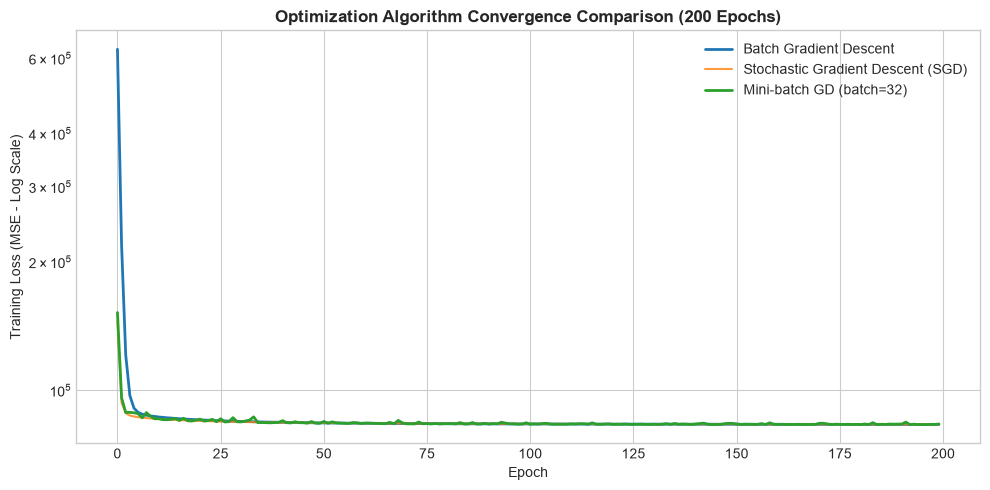

In [12]:
# 1. Batch GD
bgd = SGDRegressor(loss='squared_error', penalty='l2', alpha=0.0001, learning_rate='constant', eta0=0.001, max_iter=1, warm_start=True, random_state=42)
bgd_losses = []
for epoch in range(200):
    bgd.partial_fit(X_train_s, y_train)
    bgd_losses.append(np.mean((y_train - bgd.predict(X_train_s)) ** 2))

# 2. Stochastic GD
sgd = SGDRegressor(loss='squared_error', penalty='l2', alpha=0.0001, learning_rate='invscaling', eta0=0.01, power_t=0.25, max_iter=1, warm_start=True, random_state=42)
sgd_losses = []
for epoch in range(200):
    sgd.partial_fit(X_train_s, y_train)
    sgd_losses.append(np.mean((y_train - sgd.predict(X_train_s)) ** 2))

# 3. Mini-batch GD (B=32)
mbgd = SGDRegressor(loss='squared_error', penalty='l2', alpha=0.0001, learning_rate='invscaling', eta0=0.01, power_t=0.25, max_iter=1, warm_start=True, random_state=42)
mbgd_losses = []
for epoch in range(200):
    indices = np.random.RandomState(epoch).permutation(len(X_train_s))
    for start in range(0, len(X_train_s), 32):
        batch = indices[start:start+32]
        mbgd.partial_fit(X_train_s[batch], y_train[batch])
    mbgd_losses.append(np.mean((y_train - mbgd.predict(X_train_s)) ** 2))

plt.figure(figsize=(10, 5))
plt.plot(bgd_losses, label='Batch Gradient Descent', linewidth=2)
plt.plot(sgd_losses, label='Stochastic Gradient Descent (SGD)', linewidth=1.5, alpha=0.8)
plt.plot(mbgd_losses, label='Mini-batch GD (batch=32)', linewidth=2)
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Training Loss (MSE - Log Scale)')
plt.title('Optimization Algorithm Convergence Comparison (200 Epochs)', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()


---
## 11. Validation Performance Summary & Model Selection

Comparative summary of all regression models on the validation set.


In [13]:
val_summary = pd.DataFrame([
    res_baseline, res_slr, res_mlr, res_poly, res_ridge,
    res_lasso, res_dt, res_knn, res_svr, res_bag,
    res_ada, res_stack, res_vote
]).sort_values(by='RMSE')

print("=== REGRESSION VALIDATION PERFORMANCE RANKING ===")
display(val_summary)


=== REGRESSION VALIDATION PERFORMANCE RANKING ===


,Model,MAE,MSE,RMSE,R2,MAPE (%)
9,Bagging Regressor,103.48,20768.88,144.11,0.7841,12.54
10,AdaBoost Regressor,105.60,21270.93,145.85,0.7789,13.09
11,Stacking Regressor,108.67,21446.22,146.45,0.7771,12.91
12,Voting Regressor,107.59,21558.17,146.83,0.7759,13.00
5,Lasso Regression (L1),110.59,21903.34,148.00,0.7723,13.13
4,Ridge Regression (L2),112.19,22389.04,149.63,0.7673,13.36
2,Multiple Linear Regression,112.74,22533.97,150.11,0.7658,13.42
3,Polynomial Regression (deg=2),118.73,26147.22,161.70,0.7282,14.42
8,SVR (RBF Kernel),128.10,29599.14,172.04,0.6923,15.55
1,Simple Linear Regression,128.65,29905.77,172.93,0.6891,15.53
